# Task 2b: Spindle-Ripple over time

Focus is change over time (Yixiao, Aug 2026). HC is shown as a second line.

## Two nulls

| | breaks | asks |
|---|---|---|
| Circular shift | the alignment between the two event trains | is there coupling on this day? |
| Permutation | the order of the days | is the trend across days real? |

## Measures

| Measure | What it is | Sensitive to |
|---|---|---|
| rate | sequences per NREM minute | how much the animal slept |
| ratio | observed / chance | timing only |

## Three time axes

| Axis | Question | Available for |
|---|---|---|
| `days_elapsed` | drift over the 12 weeks, mostly a control | all days |
| `gl_num` | task experience accumulated | training days only |
| `session_num` | progress within one goal location | training days only |

## Statistics (slide 11)

Spearman per rat -> permutation on day order per rat -> Wilcoxon across rats ->
Benjamini-Hochberg FDR on the across-rat tests only.

7 rats: Wilcoxon can't go below p ~0.016.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# lab repo root on the path, so `modules` imports work from this folder
REPO_ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "modules" / "project_config.py").exists()
)
sys.path.insert(0, str(REPO_ROOT))
from modules.project_config import get_path  # noqa: E402

# local paths come from config.yaml (see config.example.yaml)
ROOT = get_path("R1_8_root")  # holds Rat_HM_Ephys_TD_Analysis_R1_8 and _R9_16
assert get_path("R9_16_root") == ROOT, "these notebooks expect R1_8_root == R9_16_root"
WAVE_CACHE = get_path("event_cache_root")
SESSION_MAP_CSV = get_path("session_map_csv")
DAY_GRID_XLSX = get_path("day_grid_xlsx")
OUT = REPO_ROOT / "results" / "leticia_event_coupling"  # figures and caches
SPINDLE_METHOD = "wavelet_amp_1_ampcore_3"
PHASES = ["postsleep"]

BOUT_KEYS = ["rat", "date", "trial", "nrem_bout_index"]
AREAS = ["PL", "RSC", "HPC"]
RATS = [1, 3, 7, 8, 11, 12, 13]

N_ITER = 1000
SHIFT_RATS = RATS

MEASURES = ["rate", "ratio"]
MIN_RIPPLES = 0

FIGDIR = OUT / "task2b_overtime_figures"
FIGDIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIGDIR / f"{name}.png", dpi=200, bbox_inches="tight")
    print("saved:", name)


print("drive reachable:", ROOT.exists(), " (False is fine - we load from WAVE_CACHE)")
print("rats:", RATS, "| circular shift on:", SHIFT_RATS, "|", N_ITER, "iterations")

drive reachable: True  (False is fine - we load from WAVE_CACHE)
rats: [1, 3, 7, 8, 11, 12, 13] | circular shift on: [1, 3, 7, 8, 11, 12, 13] | 1000 iterations


## Load

Bad days are removed in `build_wave` (`excluded_days.py`).

In [2]:
from modules.event_coupling.build_tables import add_condition, build_wave

ripples = add_condition(
    build_wave(ROOT, "ripple", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)
spindles = add_condition(
    build_wave(ROOT, "spindle", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)

rip = ripples[(ripples["rat"].isin(RATS)) & (ripples["group"] != "other")]
spn = spindles[
    (spindles["rat"].isin(RATS))
    & (spindles["group"] != "other")
    & (spindles["area"].isin(AREAS))
]

print(f"{len(rip):,} ripples | {len(spn):,} spindles")
print(rip.groupby("group").size().to_string())

ripple: 16 units to gather
  excluded 18,567 rows from 16 bad recording days
  36,373 rows had no trial number (16 rat-days) -> filled with 1
spindle: 48 units to gather
  excluded 12,114 rows from 16 bad recording days
  16,338 rows had no trial number (16 rat-days) -> filled with 1
515,364 ripples | 163,477 spindles
group
HC          188361
Training    327003


In [ ]:
print(spn.groupby("area").size().to_string())
print("spindles per rat:")
print(spn.groupby(["rat", "area"]).size().unstack(fill_value=0).to_string())
print("duration (s):")
print(spn["spindle_duration_s"].describe().round(2).to_string())

### Check that the bad days were dropped

In [3]:
from modules.event_coupling.excluded_days import excluded_table

ex = excluded_table()
check = ex.merge(
    rip[["rat", "date"]]
    .assign(date=pd.to_datetime(rip["date"]).dt.normalize())
    .drop_duplicates(),
    on=["rat", "date"],
)
print(
    f"{len(ex)} rat-days on the exclusion list | still present in the data: {len(check)} (want 0)"
)
assert len(check) == 0, "exclusion did not fire - is excluded_days.py in this folder?"

42 rat-days on the exclusion list | still present in the data: 0 (want 0)


## Time labels

In [4]:
from modules.event_coupling.gl_sessions import add_gl_sessions, build_gl_sessions
from modules.event_coupling.hc_sessions import add_session_type, build_day_table


def prep_keys(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df["rat"] = df["rat"].astype("int64")
    return df


gl = prep_keys(build_gl_sessions(ROOT, cache_dir=WAVE_CACHE, rebuild=False))
days = add_session_type(build_day_table(DAY_GRID_XLSX, verbose=False))


def add_context(df):
    df = add_gl_sessions(prep_keys(df), gl)
    return df.merge(
        prep_keys(days)[["rat", "date", "session_type"]].drop_duplicates(),
        on=["rat", "date"],
        how="left",
    )


rip_ctx = add_context(rip)
spn_ctx = add_context(spn)

# days since each rat's first recording (gaps between sessions are 1-7 days)
first = rip_ctx.groupby("rat")["date"].transform("min")
rip_ctx["days_elapsed"] = (rip_ctx["date"] - first).dt.days
spn_ctx = spn_ctx.merge(
    rip_ctx[["rat", "date", "days_elapsed"]].drop_duplicates(),
    on=["rat", "date"],
    how="left",
)

print(
    rip_ctx.groupby(["rat", "group"])["date"]
    .nunique()
    .unstack(fill_value=0)
    .to_string()
)

group  HC  Training
rat                
1       7        12
3      11        20
7       5        10
8      10        20
11     12        19
12     12        19
13     10        19


# Measure per recording day
## Rate and ratio for every rat-day

- rate = sequences per NREM minute
- ratio = observed / chance (chance = share of NREM time covered by spindles)

Counted both ways: spindles with a ripple (Navarro Lobato) and ripples inside a spindle.

In [5]:
from modules.event_coupling import spindle_ripple as sr

RULE = "any_overlap"  # slide 7 / Navarro Lobato: partial overlaps count


def per_day(spn_df, rip_df, area, min_ripples=MIN_RIPPLES):
    """Rate and ratio for each rat x recording day, one spindle area."""
    s = spn_df[spn_df["area"] == area]
    rows = []
    for (rat, date), rg in rip_df.groupby(["rat", "date"]):
        sg = s[(s["rat"] == rat) & (s["date"] == date)]
        if sg.empty or len(rg) < max(min_ripples, 1):
            continue
        t = sr.count_overlap(sg, rg, rule=RULE)
        n_rip, n_spn = t["n_ripple"].sum(), t["n_spindle"].sum()
        if n_rip == 0 or n_spn == 0:
            continue

        nrem_min = (
            rg[BOUT_KEYS + ["nrem_bout_duration_s"]]
            .drop_duplicates(BOUT_KEYS)["nrem_bout_duration_s"]
            .sum()
            / 60
        )
        if nrem_min <= 0:
            continue

        # analytic chance, descriptive only (the circular shift is the real null)
        p_chance = (t["spindle_ms"].sum() / 1000.0) / (nrem_min * 60)
        obs_prop = t["n_coupled"].sum() / n_rip

        rows.append(
            {
                "rat": rat,
                "date": date,
                "area": area,
                "rate": t["n_spindle_coupled"].sum() / nrem_min,
                "ratio": obs_prop / p_chance if p_chance > 0 else np.nan,
                "n_seq": int(t["n_spindle_coupled"].sum()),
                "n_ripple_coupled": int(t["n_coupled"].sum()),
                "n_ripple": int(n_rip),
                "n_spindle": int(n_spn),
                "pairs": int(n_spn),
                "nrem_min": nrem_min,
                "group": rg["group"].iloc[0],
                "session_type": rg["session_type"].iloc[0],
                "gl_num": sg["gl_num"].iloc[0],
                "session_num": sg["session_num"].iloc[0],
                "days_elapsed": rg["days_elapsed"].iloc[0],
            }
        )
    return pd.DataFrame(rows)


daily = pd.concat([per_day(spn_ctx, rip_ctx, a) for a in AREAS], ignore_index=True)
print(f"{len(daily)} rat-day-area values")
print(
    daily.groupby(["area", "group"])
    .agg(
        days=("date", "nunique"),
        rats=("rat", "nunique"),
        median_seq=("n_seq", "median"),
        min_seq=("n_seq", "min"),
    )
    .to_string()
)

558 rat-day-area values
               days  rats  median_seq  min_seq
area group                                    
HPC  HC          41     7       199.0       80
     Training    78     7       210.0       38
PL   HC          41     7        51.0       13
     Training    78     7        42.0        6
RSC  HC          41     7        89.0       26
     Training    78     7       107.0        9


# Can each day be trusted?

## Circular shift per recording day

Ripple train shifted within each recording's NREM time, keeps ripple timing and removes alignment with spindles.

All seven rats, 1000 iterations.

Saved per rat in `spindle_surrogate_cache/`.

In [6]:
from pathlib import Path

SHIFT_RATS = RATS  # all seven
CACHE = OUT / "spindle_surrogate_cache"
CACHE.mkdir(parents=True, exist_ok=True)

shift_rows = []
for rat in SHIFT_RATS:
    f = CACHE / f"shift_rat{rat}_n{N_ITER}_{RULE}.csv"
    if f.exists():
        shift_rows.append(pd.read_csv(f, parse_dates=["date"]))
        print(f"  rat {rat}: loaded from cache")
        continue

    rows = []
    for area in AREAS:
        s_r = spn_ctx[(spn_ctx["rat"] == rat) & (spn_ctx["area"] == area)]
        r_r = rip_ctx[rip_ctx["rat"] == rat]
        for date, rg in r_r.groupby("date"):
            sg_day = s_r[s_r["date"] == date]
            if sg_day.empty or len(rg) < 20:
                continue
            res = sr.surrogate_overlap(
                sg_day, rg, rule=RULE, n_iter=N_ITER, seed=0, verbose=False
            )
            sl = res["spindle_level"]
            rows.append(
                {
                    "rat": rat,
                    "date": date,
                    "area": area,
                    # spindle-level: Navarro Lobato's unit
                    "obs_spindle": sl["real"],
                    "null_spindle": sl["mu"],
                    "ratio_spindle": sl["ratio"],
                    "z_spindle": sl["z"],
                    # ripple-level, reported alongside
                    "obs_ripple": res["real"],
                    "null_ripple": res["mu"],
                    "ratio_ripple": res["ratio"],
                    "z_ripple": res["z"],
                    "n_spindle": res["n_spindle"],
                    "n_ripple": res["n_ripple"],
                }
            )
        print(f"  rat {rat} {area} done")

    r = pd.DataFrame(rows)
    r.to_csv(f, index=False)  # saved as we go
    shift_rows.append(r)
    print(f"  rat {rat}: saved to {f.name}")

shifted = pd.concat(shift_rows, ignore_index=True)

print("median across recording days:")
print(
    shifted.groupby("area")[["ratio_spindle", "z_spindle", "ratio_ripple", "z_ripple"]]
    .median()
    .round(3)
    .to_string()
)

  rat 1 PL done
  rat 1 RSC done
  rat 1 HPC done
  rat 1: saved to shift_rat1_n1000_any_overlap.csv
  rat 3 PL done
  rat 3 RSC done
  rat 3 HPC done
  rat 3: saved to shift_rat3_n1000_any_overlap.csv
  rat 7 PL done
  rat 7 RSC done
  rat 7 HPC done
  rat 7: saved to shift_rat7_n1000_any_overlap.csv
  rat 8 PL done
  rat 8 RSC done
  rat 8 HPC done
  rat 8: saved to shift_rat8_n1000_any_overlap.csv
  rat 11 PL done
  rat 11 RSC done
  rat 11 HPC done
  rat 11: saved to shift_rat11_n1000_any_overlap.csv
  rat 12 PL done
  rat 12 RSC done
  rat 12 HPC done
  rat 12: saved to shift_rat12_n1000_any_overlap.csv
  rat 13 PL done
  rat 13 RSC done
  rat 13 HPC done
  rat 13: saved to shift_rat13_n1000_any_overlap.csv
median across recording days:
      ratio_spindle  z_spindle  ratio_ripple  z_ripple
area                                                  
HPC           1.817     10.836         2.106    13.051
PL            1.079      0.588         1.106     0.660
RSC           1.608      5.5

In [7]:
pl = shifted[shifted["area"] == "PL"]
print(pl[["z_spindle", "n_spindle", "n_ripple"]].describe().round(2).to_string())
print("PL days with z > 2:", int((pl["z_spindle"] > 2).sum()), "of", len(pl))
print(
    "correlation between z and n_spindle:",
    round(pl["z_spindle"].corr(pl["n_spindle"]), 3),
)

       z_spindle  n_spindle  n_ripple
count     186.00     186.00    186.00
mean        0.70     167.32   2770.77
std         1.38      72.66   1060.96
min        -2.58      34.00    542.00
25%        -0.31     107.25   2024.25
50%         0.59     164.50   2555.00
75%         1.62     218.75   3200.75
max         4.47     375.00   5773.00
PL days with z > 2: 32 of 186
correlation between z and n_spindle: 0.093


Ratio near 1 with small z = no more coupling than chance.

saved: 12d_ratio_distribution_per_rat


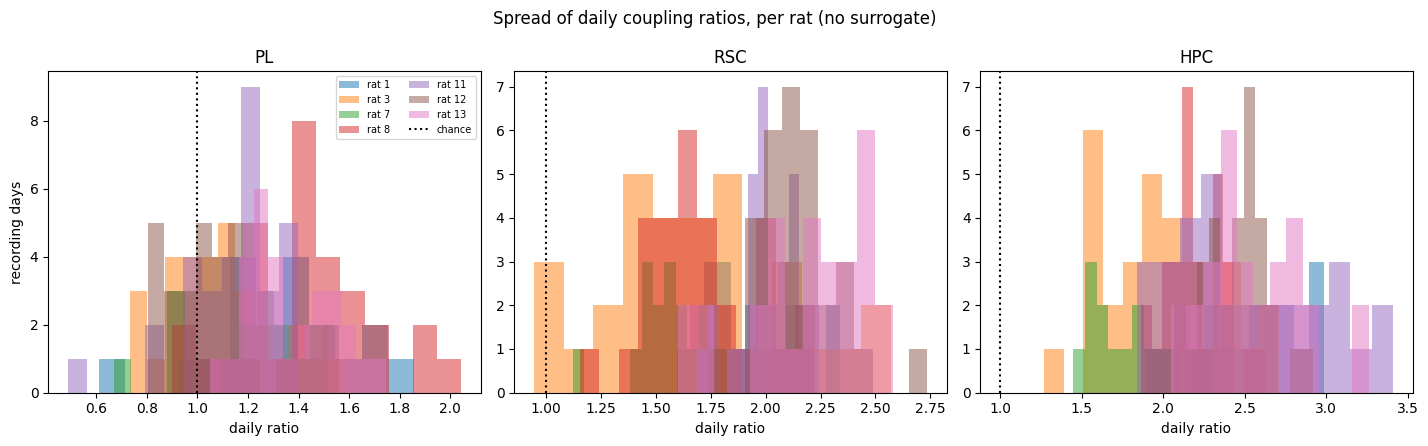

In [8]:
fig, axes = plt.subplots(1, len(AREAS), figsize=(4.8 * len(AREAS), 4.5), sharey=False)
for ax, area in zip(axes, AREAS):
    s = daily[daily["area"] == area]
    rats = sorted(s["rat"].unique())
    for i, rat in enumerate(rats):
        r = s[s["rat"] == rat]["ratio"].dropna()
        if len(r) < 3:
            continue
        ax.hist(r, bins=12, alpha=0.5, label=f"rat {rat}")
    ax.axvline(1, color="k", lw=1.5, ls=":", label="chance")
    ax.set_title(area)
    ax.set_xlabel("daily ratio")
axes[0].set_ylabel("recording days")
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle("Spread of daily coupling ratios, per rat (no surrogate)", fontsize=12)
plt.tight_layout()
save_fig(fig, "12d_ratio_distribution_per_rat")
plt.show()

## Per-rat significance

Does every rat show the coupling, or only a few?

saved: 12b_significance_per_rat


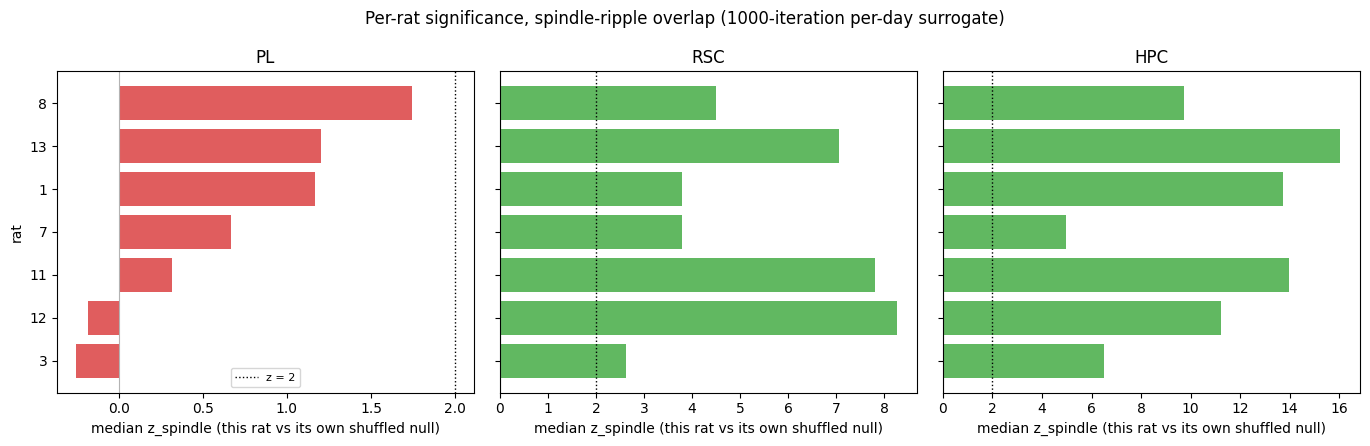

area
HPC    100% of 7 rats
PL       0% of 7 rats
RSC    100% of 7 rats


In [9]:
fig, axes = plt.subplots(1, len(AREAS), figsize=(4.6 * len(AREAS), 4.5), sharey=True)
for ax, area in zip(axes, AREAS):
    s = shifted[shifted["area"] == area]
    med = s.groupby("rat")["z_spindle"].median().sort_values()
    colours = ["tab:red" if v < 2 else "tab:green" for v in med.values]
    ax.barh(med.index.astype(str), med.values, color=colours, alpha=0.75)
    ax.axvline(2, color="k", lw=1, ls=":", label="z = 2")
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_title(area)
    ax.set_xlabel("median z_spindle (this rat vs its own shuffled null)")
axes[0].set_ylabel("rat")
axes[0].legend(fontsize=8)
fig.suptitle(
    "Per-rat significance, spindle-ripple overlap (1000-iteration per-day surrogate)",
    fontsize=12,
)
plt.tight_layout()
save_fig(fig, "12b_significance_per_rat")
plt.show()

print(
    shifted.groupby(["area", "rat"])["z_spindle"]
    .median()
    .reset_index()
    .groupby("area")["z_spindle"]
    .apply(lambda x: f"{(x >= 2).mean():.0%} of {len(x)} rats")
    .to_string()
)

## Minimum-events threshold?

Checks if days with few events give less reliable ratios.

If low-count days spread much more than the rest, a threshold is needed; otherwise keep all days.

saved: 00_threshold_check


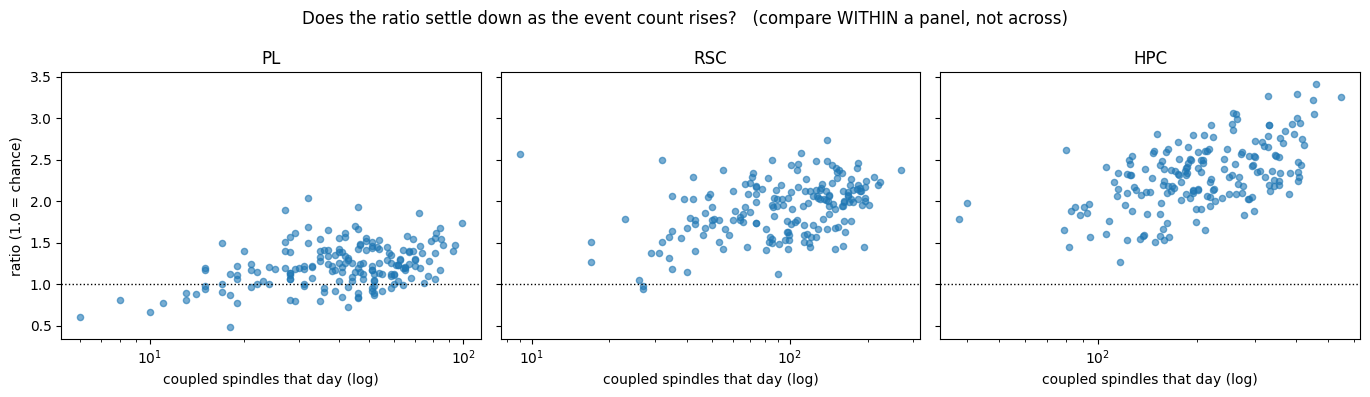

ratio by how much data that day held -- within each area:

--- PL ---
              n  median     sd     lo     hi
bin                                         
lowest 25%   47   1.112  0.274  0.487  1.902
2nd          47   1.254  0.255  0.733  2.042
3rd          48   1.212  0.252  0.839  1.929
highest 25%  44   1.293  0.207  0.988  1.857
--- RSC ---
              n  median     sd     lo     hi
bin                                         
lowest 25%   48   1.739  0.363  0.945  2.571
2nd          46   1.943  0.317  1.123  2.501
3rd          45   2.035  0.311  1.449  2.735
highest 25%  47   2.076  0.253  1.424  2.468
--- HPC ---
              n  median     sd     lo     hi
bin                                         
lowest 25%   48   2.025  0.368  1.269  2.815
2nd          45   2.243  0.293  1.538  2.807
3rd          46   2.336  0.346  1.662  3.071
highest 25%  47   2.551  0.360  1.887  3.410
If the median is flat across the four bins within an area, thin days
behave like the rest and no

In [10]:
fig, axes = plt.subplots(1, len(AREAS), figsize=(4.6 * len(AREAS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, area in zip(axes, AREAS):
    s = daily[daily["area"] == area]
    ax.scatter(s["n_seq"], s["ratio"], s=20, alpha=0.6)
    ax.axhline(1, color="k", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_xlabel("coupled spindles that day (log)")
    ax.set_title(area)
axes[0].set_ylabel("ratio (1.0 = chance)")
fig.suptitle(
    "Does the ratio settle down as the event count rises?   "
    "(compare WITHIN a panel, not across)"
)
plt.tight_layout()
save_fig(fig, "00_threshold_check")
plt.show()

# quartiles within each area
print("ratio by how much data that day held -- within each area:\n")
for area in AREAS:
    s = daily[daily["area"] == area]
    q = s.assign(
        bin=pd.qcut(s["n_seq"], 4, labels=["lowest 25%", "2nd", "3rd", "highest 25%"])
    )
    print(f"--- {area} ---")
    print(
        q.groupby("bin", observed=True)["ratio"]
        .agg(n="size", median="median", sd="std", lo="min", hi="max")
        .round(3)
        .to_string()
    )

print("If the median is flat across the four bins within an area, thin days")
print("behave like the rest and no threshold is needed.")

In [11]:
for area in AREAS:
    s = daily[daily["area"] == area]
    print(
        f"{area}: correlation between days_elapsed and n_seq =",
        round(s["days_elapsed"].corr(s["n_seq"]), 3),
    )

PL: correlation between days_elapsed and n_seq = 0.067
RSC: correlation between days_elapsed and n_seq = -0.167
HPC: correlation between days_elapsed and n_seq = -0.072


# Over time
## Every recording day per rat

Separate trend lines for HC and Training.

x = days since first recording.

Point size = number of sequences.

Rat-days with less than 10 min of NREM are removed from here on (listed in red under each plot).

In [12]:
MIN_NREM_MIN = 10  # minutes of NREM sleep required for a rat-day to count
# applied from here on (over-time plots, tables, trend tests), not to the checks above

keep = daily["nrem_min"] >= MIN_NREM_MIN
nrem_removed = (
    daily.loc[~keep, ["rat", "date", "group", "nrem_min"]]
    .drop_duplicates(["rat", "date"])
    .sort_values(["rat", "date"])
    .reset_index(drop=True)
)
daily_nrem = daily[keep].reset_index(drop=True)
print(
    f"rat-days: {daily['date'].groupby(daily['rat']).nunique().sum()} -> "
    f"{daily_nrem['date'].groupby(daily_nrem['rat']).nunique().sum()} with >= {MIN_NREM_MIN} min "
    f"NREM ({len(nrem_removed)} removed)"
)
if len(nrem_removed):
    print(
        nrem_removed.assign(
            date=nrem_removed["date"].dt.strftime("%d/%m/%y")
        ).to_string(index=False, float_format=lambda v: f"{v:.1f}")
    )


def add_nrem_footnote(fig, rats=None, groups=("HC", "Training")):
    """List the rat-days removed by the NREM cutoff under the figure."""
    rem = nrem_removed[nrem_removed["group"].isin(groups)]
    if rats is not None:
        rem = rem[rem["rat"].isin(rats)]
    if rem.empty:
        return
    parts = []
    for rat, g in rem.groupby("rat"):
        days = ", ".join(
            f"{pd.Timestamp(d).date()} {grp} ({m:.1f} min)"
            for d, grp, m in zip(g["date"], g["group"], g["nrem_min"])
        )
        parts.append(f"Rat {rat}: {days}")
    note = f"Removed, < {MIN_NREM_MIN} min NREM: " + " | ".join(parts)
    fig.text(
        0.5,
        -0.01,
        note,
        ha="center",
        va="top",
        fontsize=8,
        color="firebrick",
        wrap=True,
    )

rat-days: 186 -> 186 with >= 10 min NREM (0 removed)


saved: 01_rate_PL


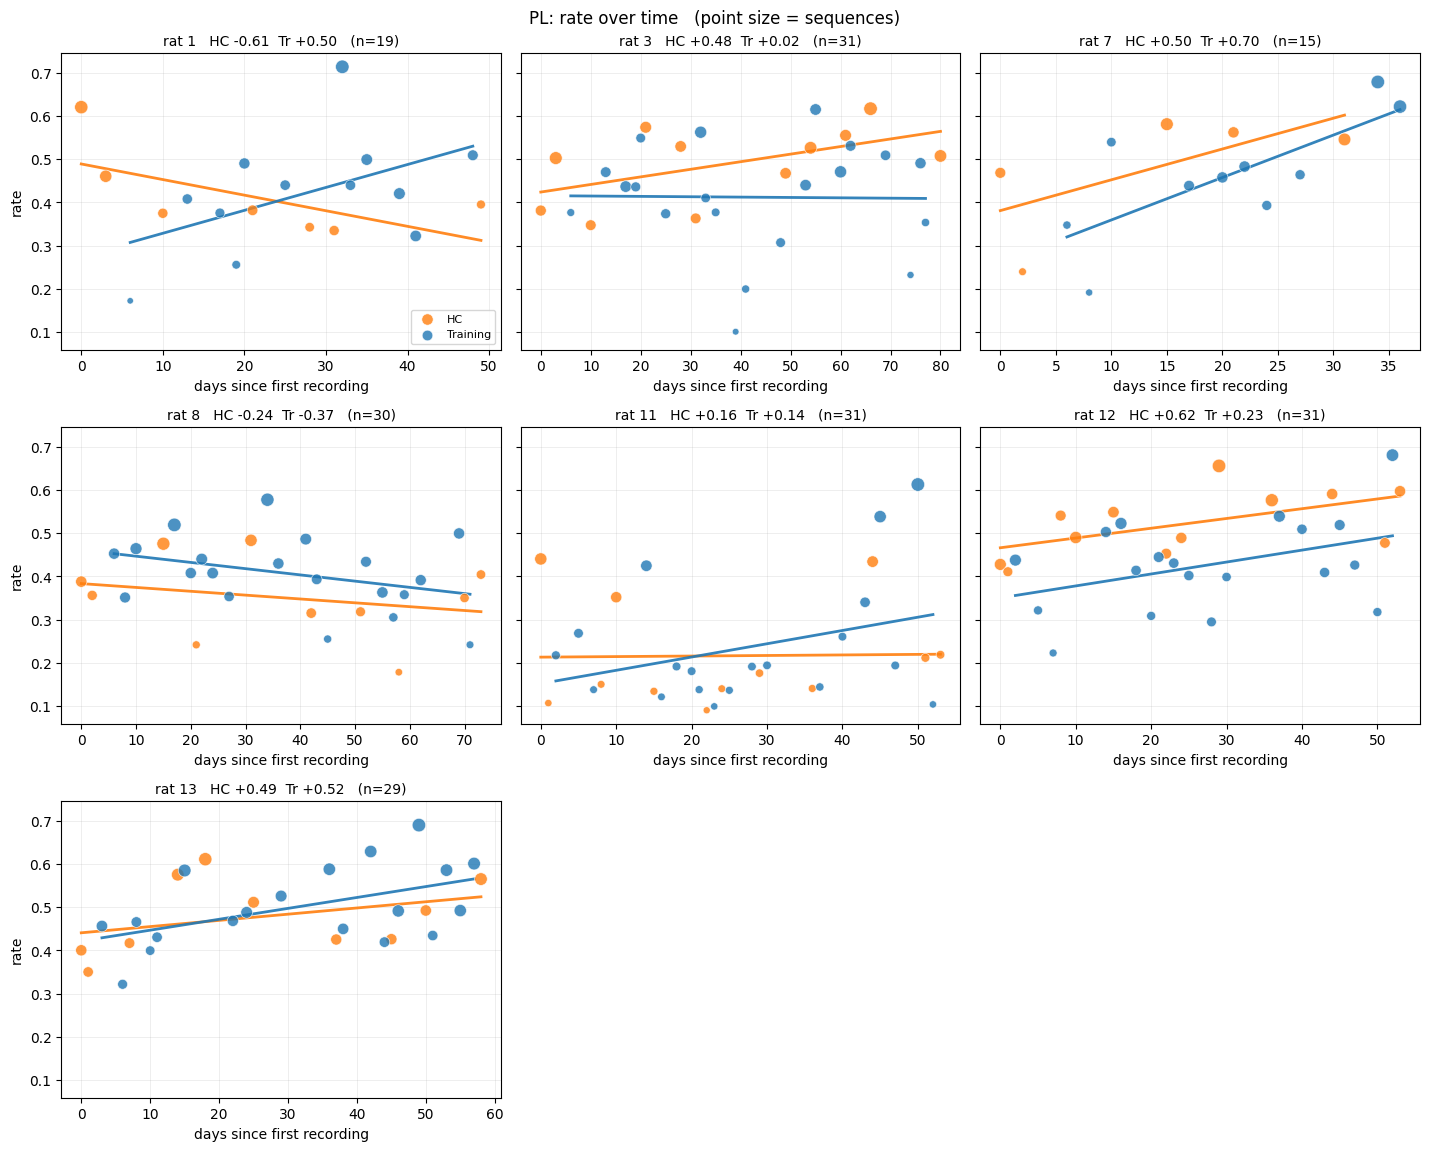

saved: 01_rate_RSC


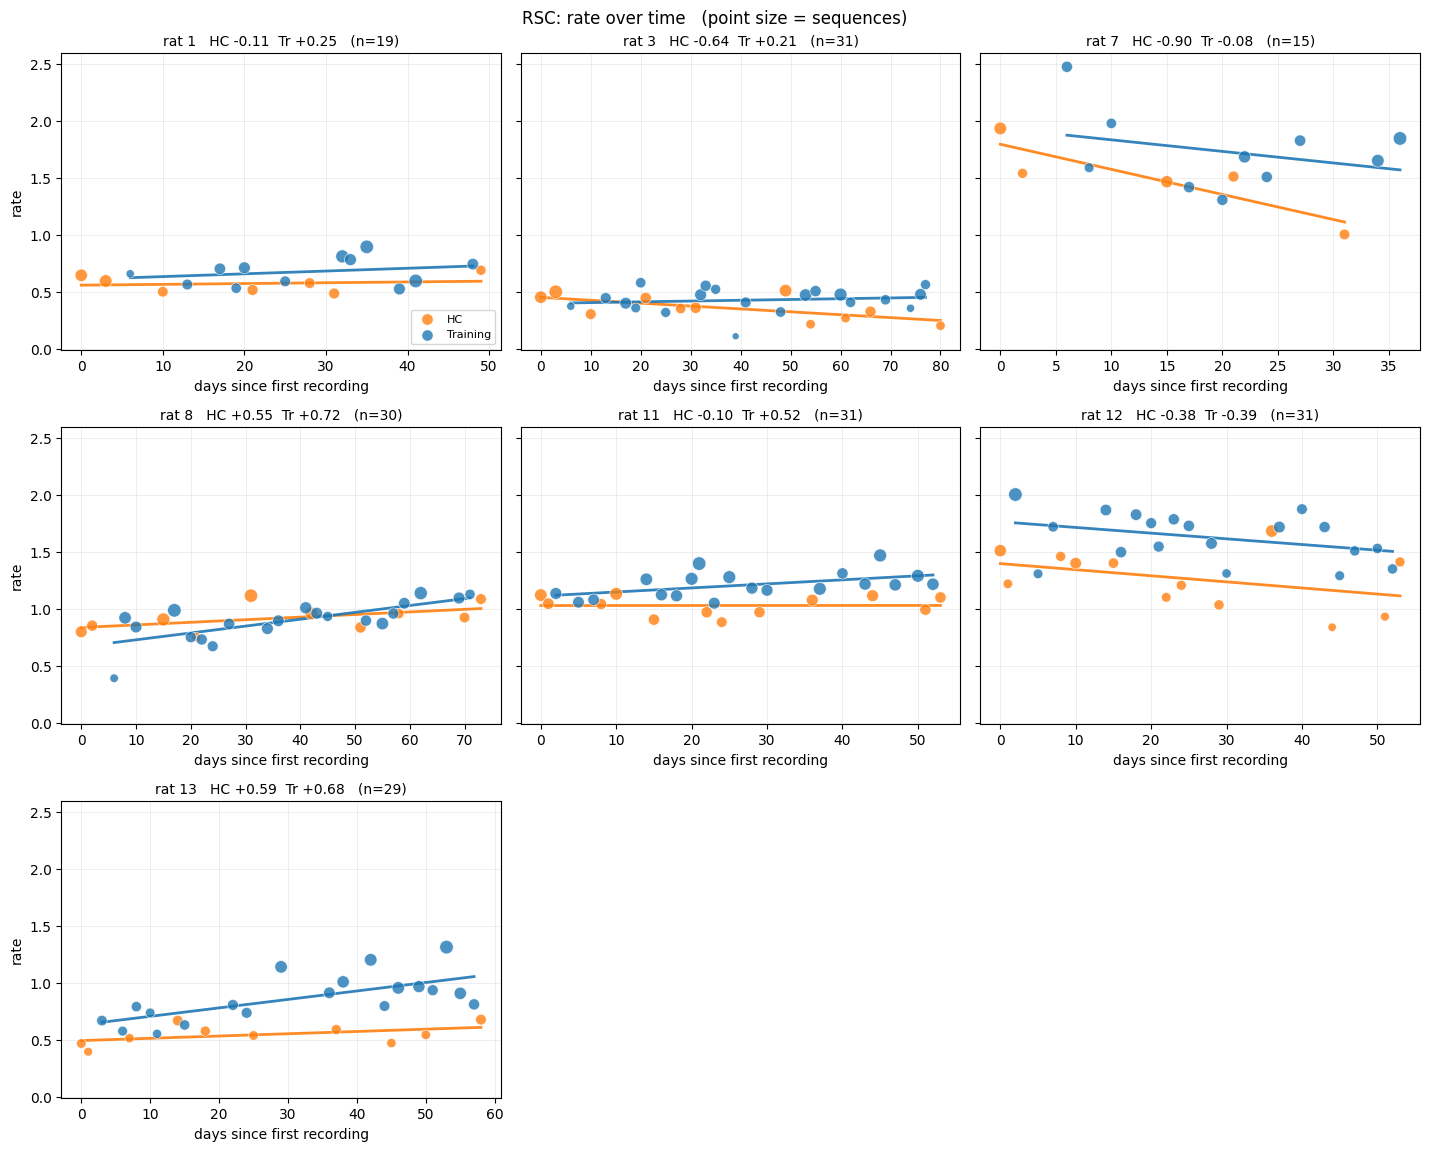

saved: 01_rate_HPC


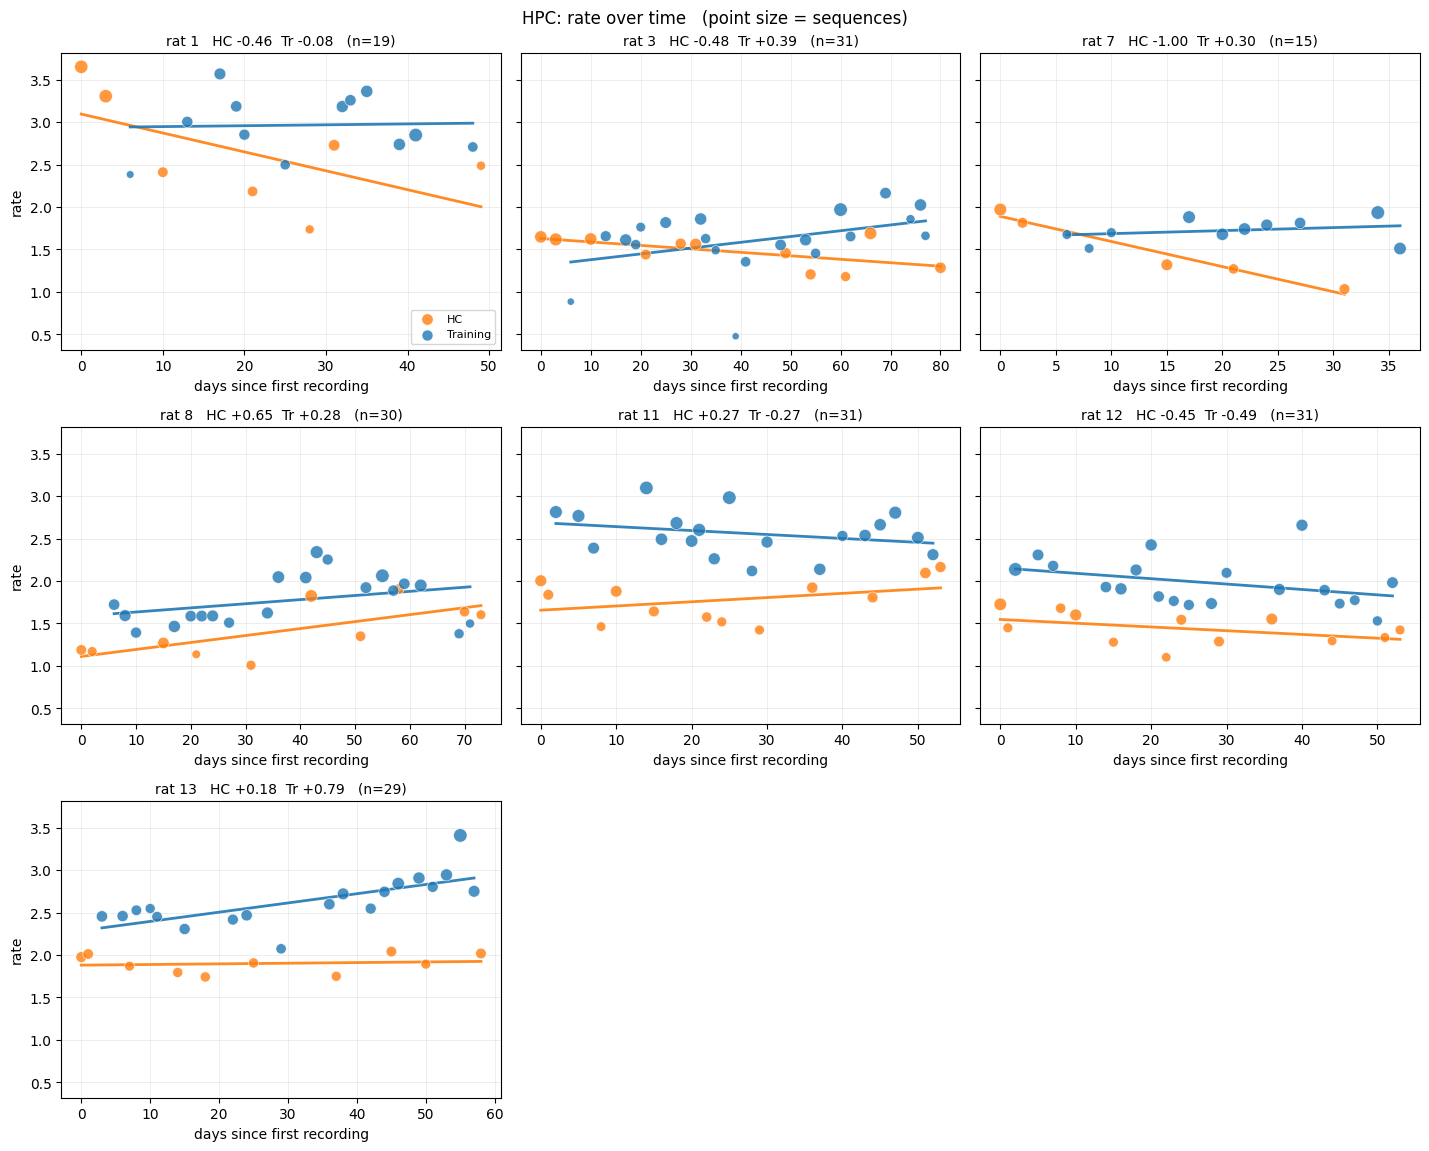

saved: 01_ratio_PL


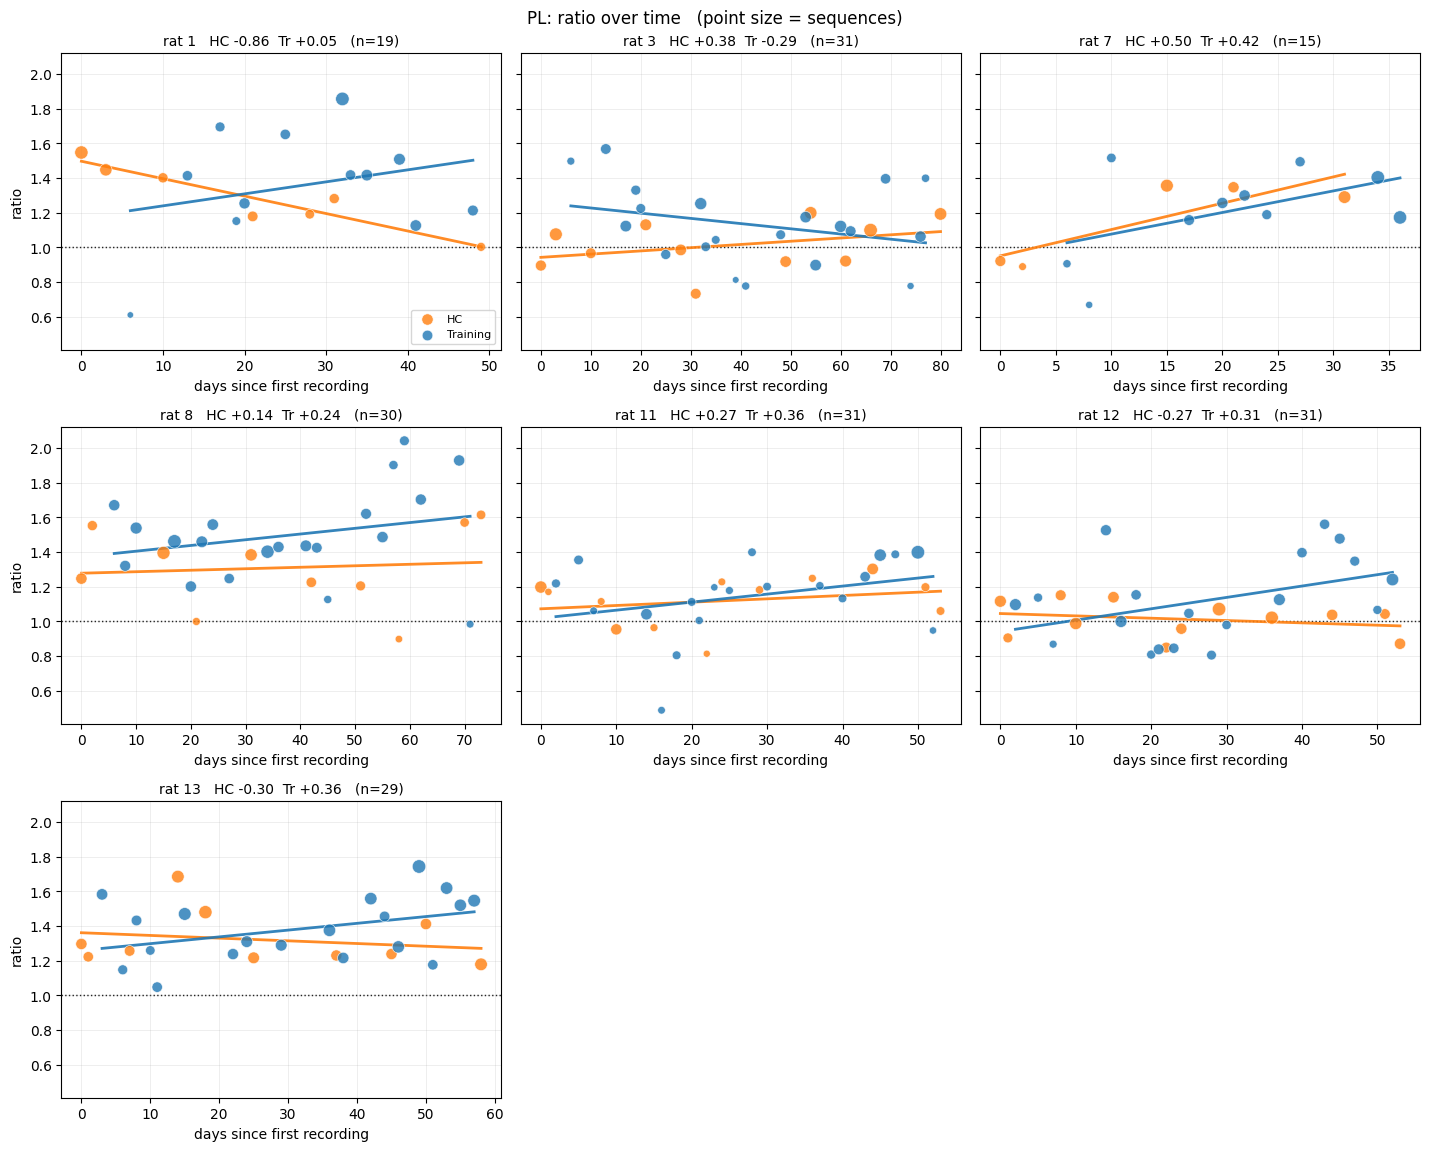

saved: 01_ratio_RSC


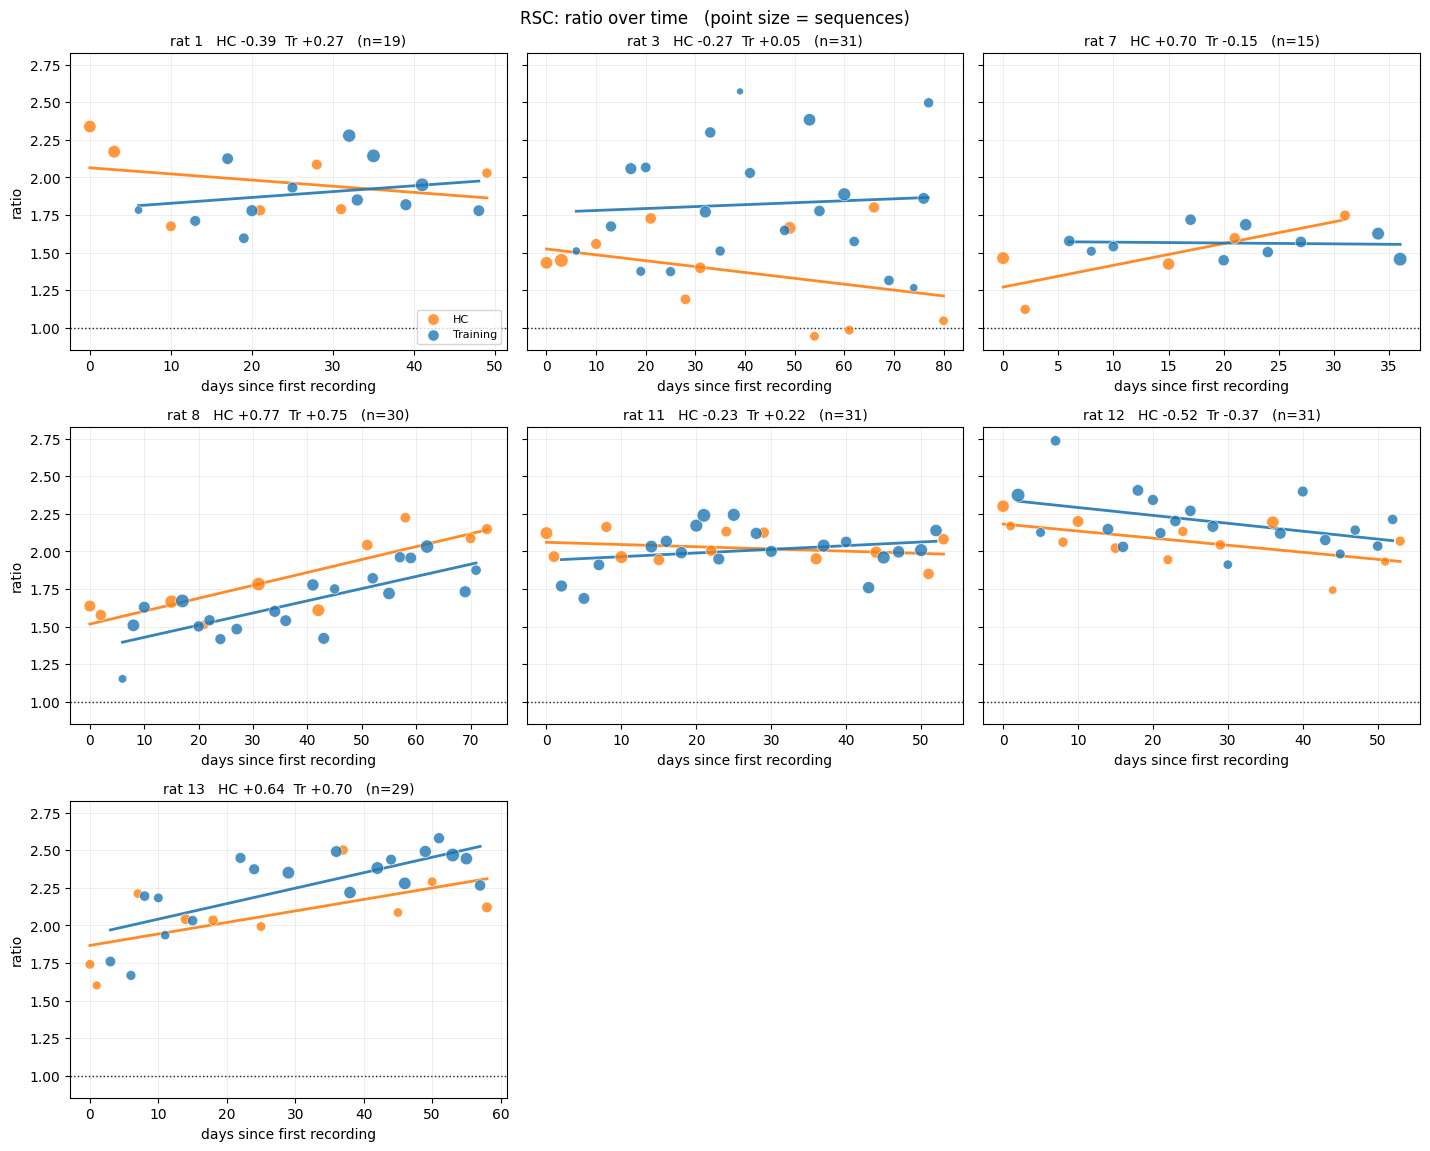

saved: 01_ratio_HPC


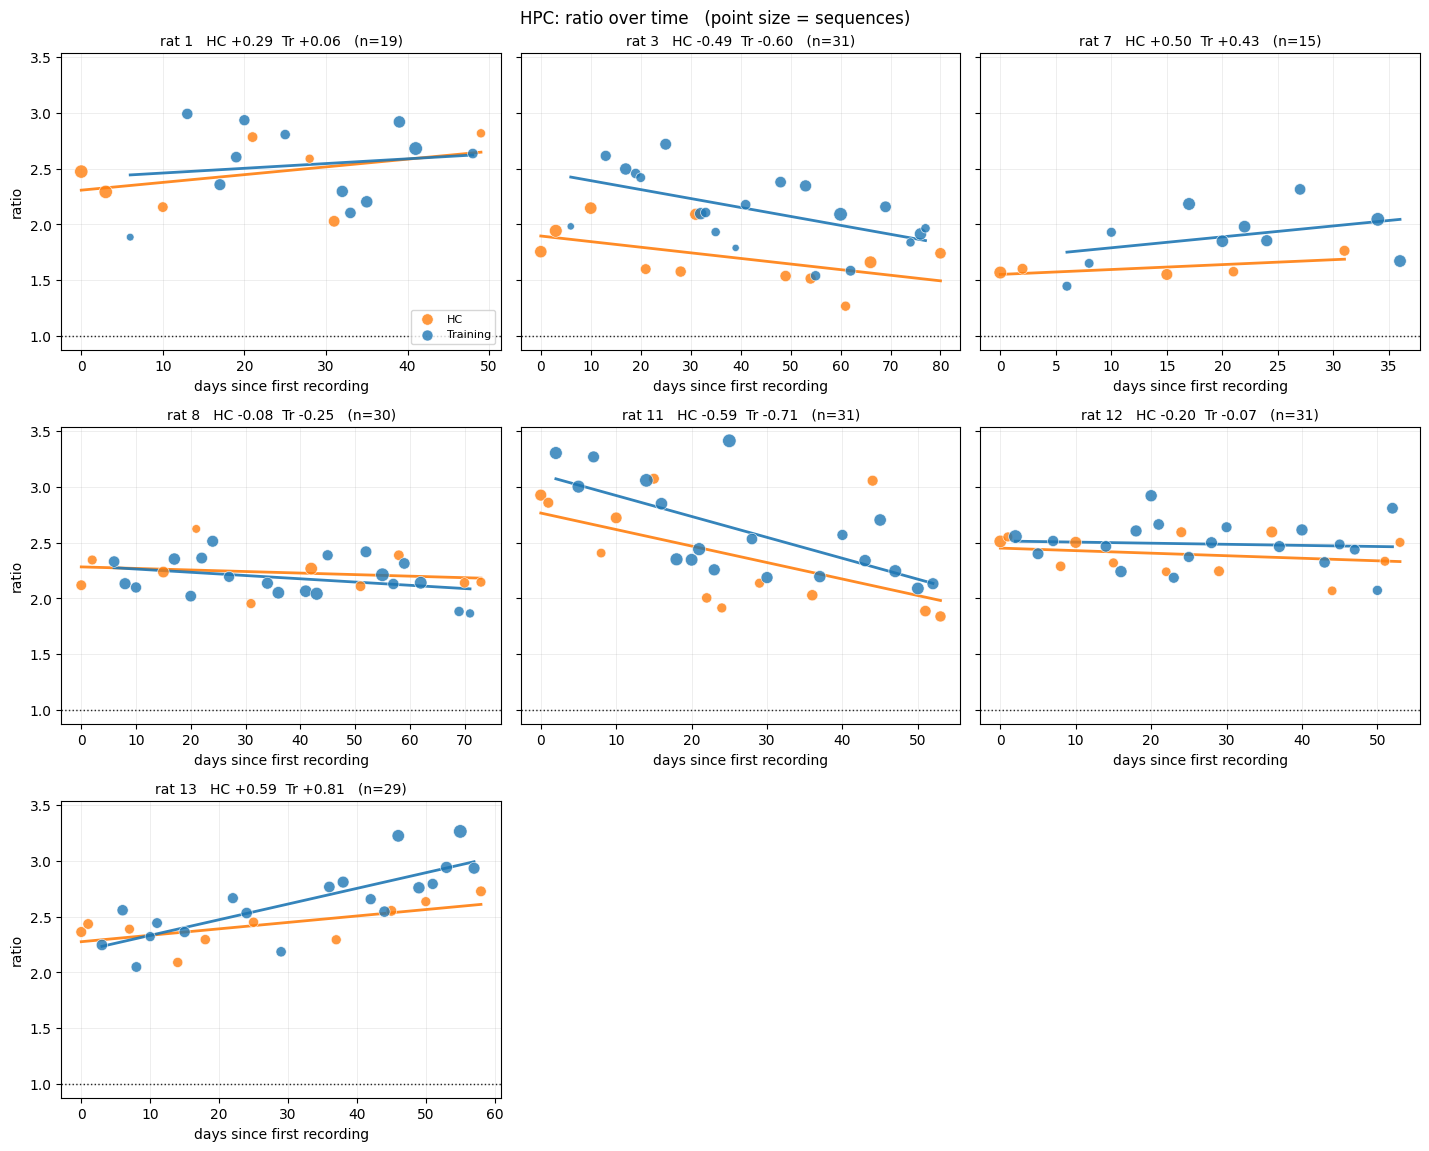

In [13]:
for measure in MEASURES:
    for area in AREAS:
        sub = daily_nrem[daily_nrem["area"] == area]
        rats = sorted(sub["rat"].unique())
        ncol = 3
        nrow = int(np.ceil(len(rats) / ncol))
        fig, axes = plt.subplots(
            nrow, ncol, figsize=(4.8 * ncol, 3.9 * nrow), sharey=True, squeeze=False
        )

        for ax, rat in zip(axes.ravel(), rats):
            r = sub[sub["rat"] == rat].sort_values("days_elapsed")
            smax = max(r["n_seq"].max(), 1)
            bits = []
            for grp, colour in [("HC", "tab:orange"), ("Training", "tab:blue")]:
                g = r[r["group"] == grp]
                if g.empty:
                    continue
                ax.scatter(
                    g["days_elapsed"],
                    g[measure],
                    s=g["n_seq"] / smax * 80 + 15,
                    alpha=0.8,
                    color=colour,
                    edgecolor="white",
                    linewidth=0.5,
                    label=grp,
                    zorder=3,
                )
                if len(g) >= 4:
                    b, a = np.polyfit(g["days_elapsed"], g[measure], 1)
                    xs = np.array([g["days_elapsed"].min(), g["days_elapsed"].max()])
                    ax.plot(xs, a + b * xs, color=colour, lw=2, alpha=0.9, zorder=2)
                    rho, pv = spearmanr(g["days_elapsed"], g[measure])
                    bits.append(f"{grp[:2]} {rho:+.2f}")
            if measure == "ratio":
                ax.axhline(1, color="k", lw=1, ls=":", zorder=1)
            ax.set_title(
                f"rat {rat}   " + "  ".join(bits) + f"   (n={len(r)})", fontsize=10
            )
            ax.set_xlabel("days since first recording")
            ax.grid(alpha=0.25, lw=0.6)

        for ax in axes.ravel()[len(rats) :]:
            ax.axis("off")
        for row in axes:
            row[0].set_ylabel(measure)
        axes[0][0].legend(fontsize=8, loc="lower right")
        fig.suptitle(
            f"{area}: {measure} over time   (point size = sequences)", fontsize=12
        )
        plt.tight_layout()
        add_nrem_footnote(fig, rats=rats)
        save_fig(fig, f"01_{measure}_{area}")
        plt.show()

### The numbers behind the points

In [14]:
cols = [
    "rat",
    "date",
    "days_elapsed",
    "group",
    "n_seq",
    "pairs",
    "nrem_min",
    "rate",
    "ratio",
]
t = (
    daily_nrem[daily_nrem["area"] == AREAS[0]]
    .assign(date=lambda d: pd.to_datetime(d["date"]).dt.strftime("%d/%m/%y"))
    .sort_values(["rat", "days_elapsed"])[cols]
)
print(f"=== {AREAS[0]} ===")
print(t.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("totals per rat, all areas:")
print(
    daily_nrem.groupby(["area", "rat"])
    .agg(
        days=("date", "nunique"),
        total_seq=("n_seq", "sum"),
        median_seq=("n_seq", "median"),
    )
    .to_string()
)

=== PL ===
 rat     date  days_elapsed    group  n_seq  pairs  nrem_min  rate  ratio
   1 23/09/22             0       HC     69    197   111.217 0.620  1.548
   1 26/09/22             3       HC     57    184   123.767 0.461  1.448
   1 29/09/22             6 Training      6     36    34.833 0.172  0.610
   1 03/10/22            10       HC     35    120    93.367 0.375  1.402
   1 06/10/22            13 Training     36    125    88.267 0.408  1.414
   1 10/10/22            17 Training     32    107    85.233 0.375  1.695
   1 12/10/22            19 Training     22    100    86.033 0.256  1.152
   1 13/10/22            20 Training     44    132    89.767 0.490  1.254
   1 14/10/22            21       HC     39    150   102.150 0.382  1.179
   1 18/10/22            25 Training     37    108    84.100 0.440  1.652
   1 21/10/22            28       HC     29    107    84.650 0.343  1.191
   1 24/10/22            31       HC     35    117   104.517 0.335  1.282
   1 25/10/22            32

---
# Trend statistics
## Per rat: Spearman + permutation on day order

Day order shuffled 1000 times.

Descriptive only.

In [15]:
from modules.event_coupling import overtime_stats as ot

AXES = {
    "days_elapsed": "days since first recording",
    "gl_num": "goal location",
    "session_num": "session within block",
}

train_daily = daily_nrem[daily_nrem["group"] == "Training"]

per_rat = []
for axis in AXES:
    src = daily if axis == "days_elapsed" else train_daily
    for measure in MEASURES:
        t = ot.trend_per_rat(
            src,
            axis,
            y_col=measure,
            group_cols=("area",),
            min_points=5,
            n_iter=1000,
            seed=0,
        )
        if len(t):
            per_rat.append(t.assign(axis=axis, measure=measure))
per_rat = pd.concat(per_rat, ignore_index=True)

print(
    per_rat[["axis", "measure", "area", "rat", "n_days", "rho", "p_perm"]]
    .round(3)
    .to_string(index=False)
)

        axis measure area  rat  n_days    rho  p_perm
days_elapsed    rate  HPC    1      19 -0.204   0.403
days_elapsed    rate  HPC    3      31  0.144   0.468
days_elapsed    rate  HPC    7      15 -0.211   0.459
days_elapsed    rate  HPC    8      30  0.457   0.016
days_elapsed    rate  HPC   11      31  0.040   0.834
days_elapsed    rate  HPC   12      31 -0.206   0.252
days_elapsed    rate  HPC   13      29  0.468   0.009
days_elapsed    rate   PL    1      19  0.111   0.651
days_elapsed    rate   PL    3      31  0.171   0.344
days_elapsed    rate   PL    7      15  0.589   0.030
days_elapsed    rate   PL    8      30 -0.292   0.124
days_elapsed    rate   PL   11      31  0.174   0.342
days_elapsed    rate   PL   12      31  0.296   0.103
days_elapsed    rate   PL   13      29  0.508   0.005
days_elapsed    rate  RSC    1      19  0.261   0.290
days_elapsed    rate  RSC    3      31 -0.051   0.768
days_elapsed    rate  RSC    7      15 -0.232   0.407
days_elapsed    rate  RSC   

## Across rats, Wilcoxon then FDR

Wilcoxon on the seven per-rat rho values against 0.

FDR on the ~18 across-rat tests (3 axes x 3 areas x 2 measures) only.

In [16]:
summary = []
for (axis, measure), g in per_rat.groupby(["axis", "measure"]):
    res = ot.across_rats(g, group_cols=("area",), verbose=False)
    summary.append(res.assign(axis=axis, measure=measure))
summary = pd.concat(summary, ignore_index=True)

summary["p_fdr"] = ot.fdr(summary["p_wilcoxon"])
summary = summary.sort_values("p_wilcoxon")

print(
    summary[
        [
            "axis",
            "measure",
            "area",
            "n_rats",
            "median_rho",
            "n_positive",
            "p_wilcoxon",
            "p_fdr",
        ]
    ]
    .round(4)
    .to_string(index=False)
)
print(f"{len(summary)} across-rat tests, FDR-corrected together")
sig = summary[summary["p_fdr"] < 0.05]
print(f"surviving FDR: {len(sig)}")
if len(sig):
    print(
        sig[["axis", "measure", "area", "median_rho", "p_fdr"]]
        .round(4)
        .to_string(index=False)
    )

        axis measure area  n_rats  median_rho  n_positive  p_wilcoxon  p_fdr
      gl_num   ratio   PL       7      0.3257           6      0.0469 0.4018
      gl_num    rate  RSC       7      0.2720           6      0.1094 0.4018
days_elapsed    rate   PL       7      0.1738           6      0.1094 0.4018
      gl_num    rate   PL       7      0.1860           5      0.1159 0.4018
days_elapsed   ratio   PL       7      0.1571           5      0.1562 0.4018
days_elapsed   ratio  RSC       7      0.0968           6      0.1562 0.4018
 session_num    rate  HPC       7      0.0725           6      0.1562 0.4018
days_elapsed    rate  RSC       7      0.2614           4      0.2188 0.4375
      gl_num   ratio  RSC       7      0.1506           5      0.2188 0.4375
 session_num    rate   PL       7      0.0797           5      0.3750 0.6750
      gl_num    rate  HPC       7      0.3133           4      0.4688 0.7670
 session_num   ratio  HPC       7      0.1676           5      0.6875 0.9375

saved: 06_blocks_ratio_rat1


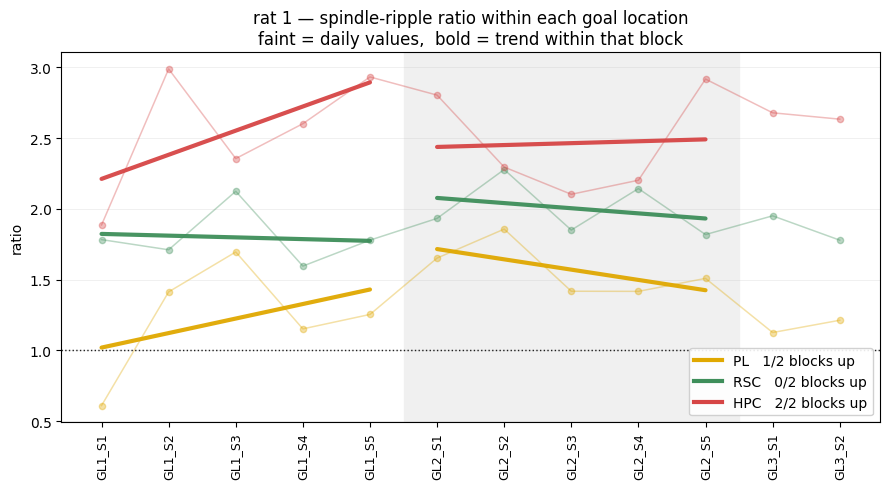

saved: 06_blocks_ratio_rat3


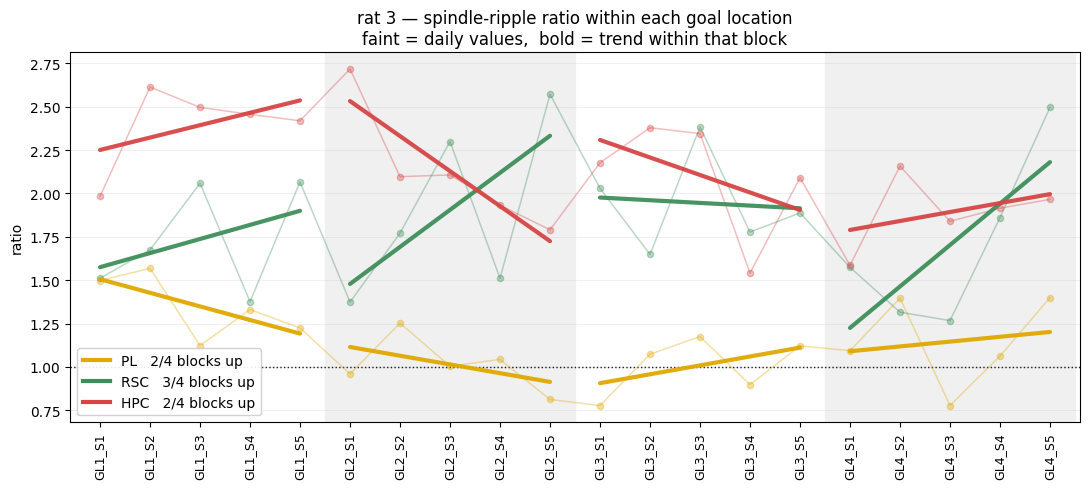

saved: 06_blocks_ratio_rat7


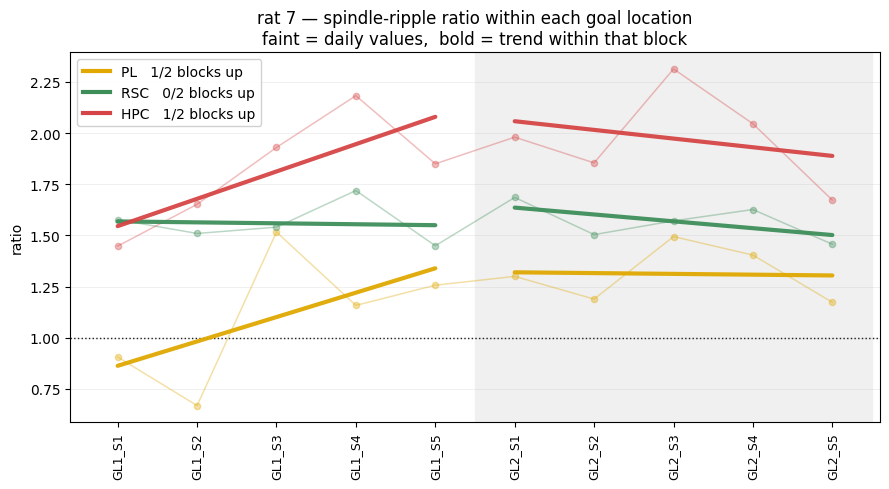

saved: 06_blocks_ratio_rat8


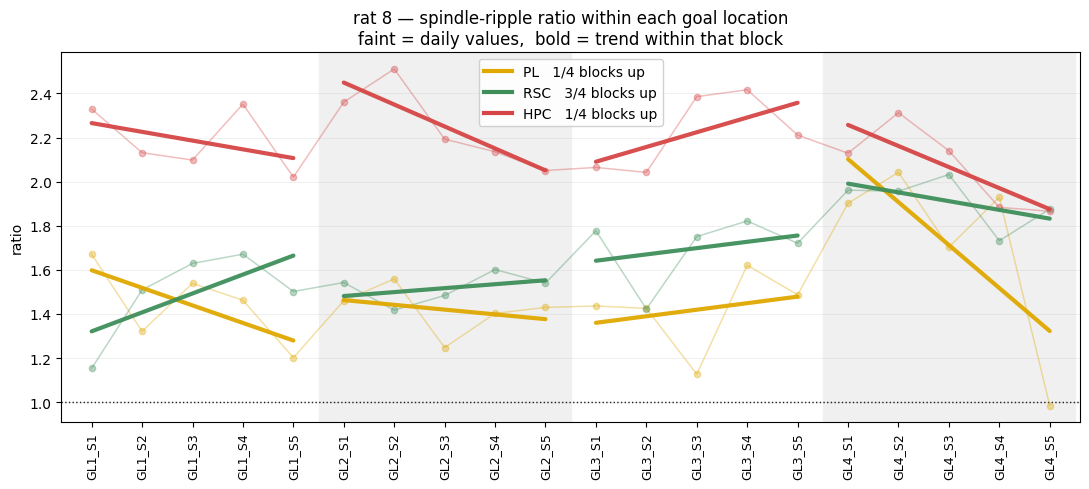

saved: 06_blocks_ratio_rat11


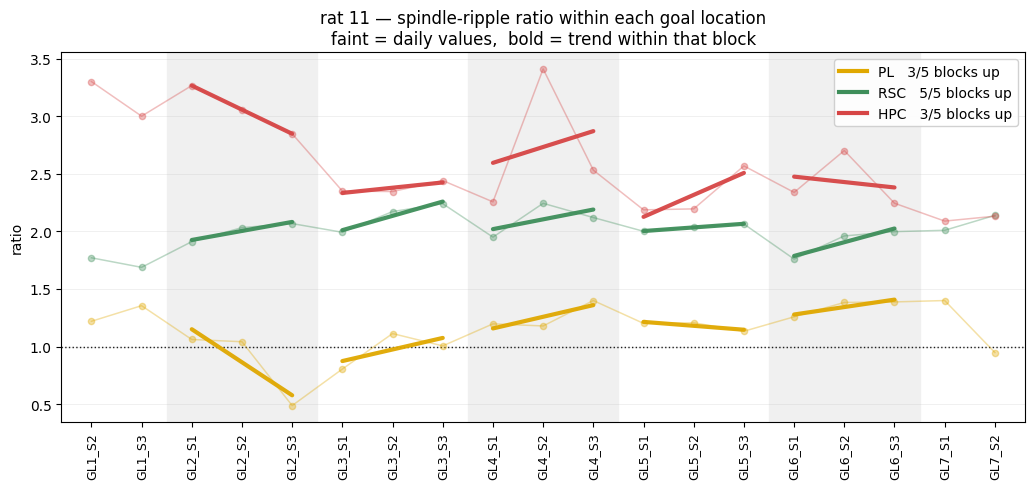

saved: 06_blocks_ratio_rat12


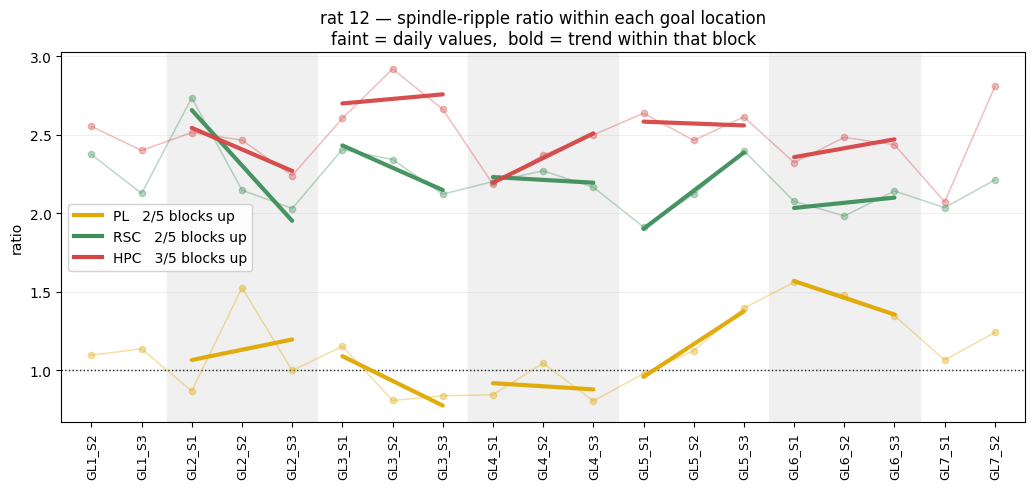

saved: 06_blocks_ratio_rat13


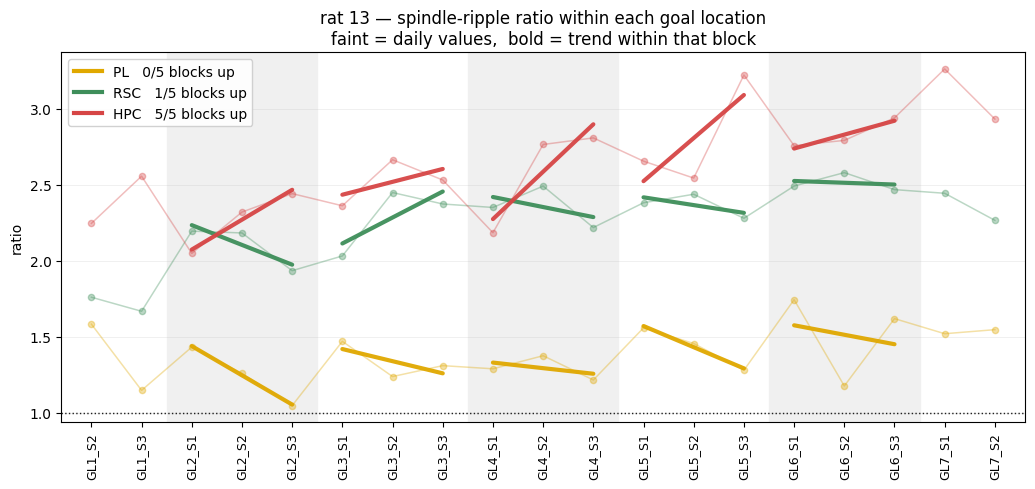

In [18]:
AREA_COLOUR = {"HPC": "#D64545", "PL": "#E0A800", "RSC": "#3E8E5A"}


def rat_block_figure(measure, rat):
    """One figure per rat. x-axis is that animal's own sequence of training days:
    GL1_S1 ... GL1_S5, GL2_S1 ... Nothing averaged across goal locations.

    Faint dots and line = daily values. Bold line = a trend fitted WITHIN each
    goal-location block, so it restarts at every new goal and a rise across a
    block's sessions is visible separately from drift across blocks.

    Areas overlaid: HPC red, PL yellow, RSC green. Training days only.
    """
    d = daily_nrem[(daily_nrem["rat"] == rat) & (daily_nrem["group"] == "Training")]
    d = d.dropna(subset=[measure, "gl_num", "session_num"]).copy()
    if d.empty:
        return

    d["step"] = d["gl_num"] * 100 + d["session_num"]
    order = sorted(d["step"].unique())
    pos = {s: i for i, s in enumerate(order)}
    labels = [f"GL{int(s // 100)}_S{int(s % 100)}" for s in order]
    d["x"] = d["step"].map(pos)

    fig, ax = plt.subplots(figsize=(max(9, 0.55 * len(order)), 5))
    tilt = {}
    for area in AREAS:
        a = d[d["area"] == area].sort_values("x")
        if a.empty:
            continue
        g = a.groupby("x")[measure].mean()
        ax.plot(
            g.index,
            g.values,
            lw=1.1,
            alpha=0.35,
            marker="o",
            ms=4.5,
            color=AREA_COLOUR[area],
            zorder=2,
        )
        ups = total = 0
        for gl in sorted(a["gl_num"].unique()):
            b = a[a["gl_num"] == gl].groupby("x")[measure].mean()
            if len(b) < 3:
                continue
            m, c = np.polyfit(b.index, b.values, 1)
            xs = np.array([b.index.min(), b.index.max()])
            ax.plot(
                xs,
                c + m * xs,
                lw=3.0,
                color=AREA_COLOUR[area],
                alpha=0.95,
                solid_capstyle="round",
                zorder=4,
            )
            total += 1
            ups += m > 0
        tilt[area] = (ups, total)

    for s in order:
        if int(s // 100) % 2 == 0:
            ax.axvspan(pos[s] - 0.5, pos[s] + 0.5, color="0.94", zorder=0)
    if measure == "ratio":
        ax.axhline(1, color="k", lw=1, ls=":", zorder=1)

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=9)
    ax.set_xlim(-0.6, len(labels) - 0.4)
    ax.set_ylabel(measure)
    ax.grid(alpha=0.22, lw=0.6, axis="y")

    handles = [
        plt.Line2D(
            [],
            [],
            color=AREA_COLOUR[a],
            lw=3,
            label=f"{a}   {tilt[a][0]}/{tilt[a][1]} blocks up" if a in tilt else a,
        )
        for a in AREAS
    ]
    ax.legend(handles=handles, fontsize=10, framealpha=0.9)
    ax.set_title(
        f"rat {rat} \u2014 spindle-ripple {measure} within each goal location\n"
        "faint = daily values,  bold = trend within that block",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig, rats=[rat], groups=["Training"])
    save_fig(fig, f"06_blocks_{measure}_rat{rat}")
    plt.show()


for rat in sorted(daily_nrem["rat"].unique()):
    rat_block_figure("ratio", rat)

# Pooled coupling and significance test

In [19]:
def plot_overlap_significance(res, area, label=None, ax=None):
    """Observed overlap count against the null distribution, with a
    significance marker (Yixiao agreed, 2 Sep 2026, as the spindle-ripple
    equivalent of the lag-histogram significance bar -- there is no lag
    axis here, so no window bar; instead the observed count is marked
    against a histogram of the shuffled counts).

    res -- output of sr.surrogate_overlap (pooled, full dataset)
    """
    null = res["null"]
    obs = res["real"]
    p = res["p"]
    sig = p < 0.05

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))

    ax.hist(null, bins=30, color="tab:orange", alpha=0.4, label="null (shuffled)")
    ax.axvline(null.mean(), color="tab:orange", lw=1.5, ls="--", label="null mean")
    ax.axvline(obs, color="tab:red" if sig else "tab:blue", lw=2.5, label="observed")

    # label top-left so it doesn't overlap the observed line
    p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.text(
        0.05,
        0.95,
        f"{p_str}\n{'significant' if sig else 'n.s.'}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        fontweight="bold",
        color="tab:red" if sig else "tab:blue",
    )

    ax.set_xlabel("spindles containing a ripple")
    ax.set_ylabel("shuffles")
    ax.set_title(label or area)
    ax.legend(fontsize=8, loc="upper right")

    if own_fig:
        plt.tight_layout()
        return fig
    return None

In [20]:
import importlib

from modules.event_coupling import spindle_ripple as sr

importlib.reload(sr)

import inspect

print("checkpoint_every" in inspect.signature(sr.surrogate_overlap).parameters)

True


In [21]:
import pickle
from pathlib import Path

CACHE_SIG_SPINDLE = OUT / "significance_cache_spindle"
CACHE_SIG_SPINDLE.mkdir(parents=True, exist_ok=True)
N_ITER_SIG = 1000
CHECKPOINT_EVERY = 200


def run_with_checkpoints_spindle(area):
    final_f = CACHE_SIG_SPINDLE / f"overlap_{area}_n{N_ITER_SIG}_{RULE}.pkl"
    ckpt_f = CACHE_SIG_SPINDLE / f"overlap_{area}_n{N_ITER_SIG}_{RULE}_partial.pkl"

    if final_f.exists():
        print(f"{area}: loaded finished result from cache")
        return pickle.load(open(final_f, "rb"))

    resume = None
    if ckpt_f.exists():
        resume = pickle.load(open(ckpt_f, "rb"))
        print(f"{area}: found checkpoint at {resume['n_done']}/{N_ITER_SIG}, resuming")

    def save_checkpoint(partial):
        pickle.dump(partial, open(ckpt_f, "wb"))
        print(f"    [checkpoint saved: {partial['n_done']}/{N_ITER_SIG}]")

    res = sr.surrogate_overlap(
        spn_ctx[spn_ctx["area"] == area],
        rip_ctx,
        rule=RULE,
        n_iter=N_ITER_SIG,
        seed=0,
        verbose=True,
        checkpoint_every=CHECKPOINT_EVERY,
        checkpoint_fn=save_checkpoint,
        resume_from=resume,
    )

    pickle.dump(res, open(final_f, "wb"))
    if ckpt_f.exists():
        ckpt_f.unlink()
    print(f"{area}: computed and cached")
    return res


sig_results_spindle = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, area in zip(axes, ["PL", "RSC", "HPC"]):
    res = run_with_checkpoints_spindle(area)
    plot_overlap_significance(res["spindle_level"], area, label=area, ax=ax)
    sig_results_spindle[area] = res["spindle_level"]

plt.tight_layout()
save_fig(fig, "12_significance_by_area")
plt.show()

for area, r in sig_results_spindle.items():
    print(
        f"{area}: observed {r['real']:,} | null mean {r['mu']:,.1f} "
        f"+/- {r['sd']:,.2f} | ratio {r['ratio']:.3f} | z {r['z']:+.2f} "
        f"| p = {r['p']:.4f} | significant = {r['p'] < 0.05}"
    )

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f371096d4f0>>
Traceback (most recent call last):
  File "/home/yixiao/anaconda3/envs/HexMazeProject/lib/python3.8/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7f36c83f7ca0> (for post_execute):



KeyboardInterrupt



# Notes

## Decisions

| Decision | Source |
|---|---|
| rate and ratio | Maingret; plan slide 8 |
| HC as its own line | Navarro Lobato |
| FDR on across-rat tests only | per-rat values are descriptive |
| spindle-level count as main count | Navarro Lobato |
| circular shift instead of shuffle | keeps each train's own rhythm |

## Still open

- Pre-sleep not used (Maingret normalise to pre-sleep).
- 4 h of post-sleep pooled, see the first-hour notebook.
- n = 7, Wilcoxon p can't go below ~0.016.